# Hit-Generation by Fragment-Based Molecular Optimization

In [1]:
#!pip install pyTDC msal

In [2]:
#!pip install safe-mol datamol pandas numpy rdkit msal 2>/dev/null | tail -n 1

In [3]:
from nv_genmol.optimizer import MolecularOptimizer
from nv_genmol.library import Library
from nv_genmol.genmol import GenMol_Generator
from nv_genmol.oracle import Oracle

import pandas as pd
import safe as sf

## Library & Seed

### Create molecular library from initial generation (2Seeds) + 100 consecutive leads

In [4]:
#df = pd.read_excel("/home/ec2-user/SageMaker/data/raw/df_ICA_bionemo_eval_20250219.xlsx")
# 
df = pd.read_csv("/home/ec2-user/SageMaker/data/raw/input-mol-inference2/sample_by_prop_from_leads_20250307_c.csv", sep='\t')
df.head(2)

,time,based_on,profile,inchikey,smiles,nearest_project_cmpd,tanimoto_similarity,sampling_dist,ai_h,hsec_total,...,logd_acid,logd_neutral,similarity_max,similarity_mean,similarity_median,MolWt,TPSA,MolLogP,sas,has_isoxazoline
0,2025-03-07 16:21:51,BCS-CN20332,profile aih wo sol,XJJKVTOJFZYGAT-UHFFFAOYSA-N,COC1(C(=O)OCCC#N)CC(c2cc(F)cc(Cl)c2)=NO1,BCS-DG87418,0.709091,0.3,287.336823,202.215942,...,2.688031,2.843356,715.490845,708.726318,704.912720,327.479218,81.477905,2.447609,3.594501,1.0
1,2025-03-07 16:21:51,BCS-CN20332,profile aih wo sol,SKMFFUNHNPOSET-UHFFFAOYSA-N,Cc1cc(CNC(=O)C2(C)CC(c3cc(F)cc(F)c3)=NO2)on1,BCS-CX72555,1.000000,0.3,279.678040,208.649658,...,2.085713,2.291817,653.023010,658.037354,656.024475,333.580261,76.660912,2.579500,3.284553,1.0


In [5]:
df1 = df.groupby('based_on').head(30)
print(df1.shape)

(60, 28)


In [6]:
df2 = pd.read_csv('../../data/interim/genmol/BCS-CN20332_R1_testmulti.csv')
df2.drop('score',axis=1,inplace=True)
df2.head(2)

,smiles
0,CCC1CCC1CC(=O)NCCC(=O)OC
1,COC(=O)CCNC(=O)COC(C)(C)C


In [7]:
df3 = pd.read_csv('../../data/interim/genmol/BCS-CE65417_R1_testmulti.csv')
df3.drop('score',axis=1,inplace=True)
df3.head(2)

,smiles
0,O=C(NCc1cccc(F)c1)C1CC([N+]Cl)=NO1
1,COC1=NOC(C(=O)NCc2cccc(I)c2)C1


In [8]:
#clean up
df1 = df1.rename(columns={"ai_h": "AIH", "hsec_total": "HSEC"})
cols = ['smiles'] #,'AIH','HSEC'
df1 = df1[cols].copy()
df1.head()

,smiles
0,COC1(C(=O)OCCC#N)CC(c2cc(F)cc(Cl)c2)=NO1
1,Cc1cc(CNC(=O)C2(C)CC(c3cc(F)cc(F)c3)=NO2)on1
2,CCCNC(=O)C1(C)CC(c2cc(C)cc(Cl)c2)=NO1
3,Cc1cc(Cl)cc(C2=NO[C@@](C)(C(=O)Nc3cccnc3)C2)c1
4,CSCCOC(=O)[C@@]1(C)CC(c2cc(Cl)cc(C#N)c2)=NO1


### Seed

In [9]:
m1 = "COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1"
m1_name = "BCS-CN20332"

## Create Oracle

In [19]:
# Test 2: With Multi-Objective.Oracle
from nv_genmol.by_genmol_oracle import MultiObjectiveOracle

#V2 with tanimoto similarity to seed
oracle = MultiObjectiveOracle(
    scoring_method="enhanced",
    logp_weight=1.0,
    mw_weight=1.0,
    similarity_weight=0.6, #reduce similarity relevance for more freedom
    use_similarity=False,
    reference_smiles=m1,
    qsar_weight=10.0, ## increased weight on QSAR
    use_qsar=True,
    qsar_model="AIH" # AIH or HSEC
)



In [20]:
# test eval with the original seed 
oracle.evaluate([m1])

{'COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1': 0.9327777846014152}

In [21]:
oracle.debug_scoring(smiles=m1)

{'score': 1.0,
 'enhanced score': 1.0,
 'properties': {'LogP': 2.5558000000000005, 'MW': 359.209},
 'normalized': {'LogP': 0.71341935483871, 'MW': 0.6052250000000001},
 'desirability': {'LogP': 0.71341935483871, 'MW': 0.3947749999999999},
 'weights': {'LogP': 0.08333333333333333,
  'MW': 0.08333333333333333,
  'QSAR_AIH': 0.8333333333333334}}

### score the initial data with this new oracle AND create final df combining the three datasets

In [22]:
# re-score original data with oracle
results = oracle.evaluate(df2['smiles'])

# results to list
values_list = list(results.values())

# cross check
print(len(values_list))
print(len(df2))

#create new score column with QSAR scores
df2['score'] = values_list
df2.sort_values(by='score',ascending=False, inplace=True)

#examples
df2.head(2)

337
337


,smiles,score
279,COC(=O)CCNC(=O)C1=CCN(c2cc(Cl)cc(Cl)c2)C1,0.722792
251,COC(=O)CCN[C@H]1CCC(C(=O)c2cc(Cl)cc(Cl)c2)C1,0.615498


In [23]:
# re-score original data with oracle
results = oracle.evaluate(df3['smiles'])

# results to list
values_list = list(results.values())

# cross check
print(len(values_list))
print(len(df3))

#create new score column with QSAR scores
df3['score'] = values_list
df3.sort_values(by='score',ascending=False, inplace=True)

#examples
df3.head(2)

236
236


,smiles,score
66,CCn1cc(CNC(=O)Cc2ccc(Br)cc2S)c(C)n1,0.662253
223,COC(=O)CCNN(C(=O)C1CCCN1)c1cc(Cl)cc(Cl)c1,0.638932


In [24]:
# re-score original data with oracle
results = oracle.evaluate(df1['smiles'])

# results to list
values_list = list(results.values())

# cross check
print(len(values_list))
print(len(df1))

#create new score column with QSAR scores
df1['score'] = values_list
df1.sort_values(by='score',ascending=False, inplace=True)

#examples
df1.head(2)

60
60


,smiles,score
969,C=CC1(C(=O)NCc2cnn(CC)c2)CC(c2cccc(Cl)c2)=NO1,0.946753
955,COC1(C(=O)NCc2cnn(C3CC3)c2)CC(c2cccc(Cl)c2)=NO1,0.946414


In [26]:
mol_library = pd.concat([df1, df3, df2], join='inner', ignore_index=True) #df1 deleted to see how it works w/o
print(mol_library.shape)
mol_library.head(2)

(633, 2)


,smiles,score
0,C=CC1(C(=O)NCc2cnn(CC)c2)CC(c2cccc(Cl)c2)=NO1,0.946753
1,COC1(C(=O)NCc2cnn(C3CC3)c2)CC(c2cccc(Cl)c2)=NO1,0.946414


## Initiate fragment library from known molecules

In [27]:
library = Library(max_fragments = 1000)

In [28]:
molecules = {r['smiles']:r['score'] for idx, r in mol_library.iterrows()}
library.update(molecules)

In [29]:
#library.fragments
library.export(2)

['c17cc(Cl)cc(Cl)c1.c16cc(Cl)cc(Cl)c1.c14ncc7cn1.NC5C3=O.C156CC1.N34',
 'O=C(C4)CCNNc1noc5n1.c15cc(Cl)cc(Cl)c1.C3(=O)N1CC6CN1.c16cc(Cl)cc(Cl)c1.N34']

## Generator

In [30]:
GENMOL_HOST = 'http://127.0.0.1:8083'
generator = GenMol_Generator(invoke_url = f"{GENMOL_HOST}/generate")

### Test generator

In [31]:
generator.produce(['CCC1CCC1CC(=O)NCCC(=O)OC'], 1)

['COCC(C)(N)c1ccc2cnnn2c1']

## Optimizer

In [32]:
optimizer = MolecularOptimizer(library = library, oracle = oracle, generator = generator)

In [33]:
data = []

In [34]:
steps=100

def eval():
    best = library.molecules.score[0]
    mean = library.molecules.head(100)['score'].mean() #50
    std = library.molecules.head(100)['score'].std()  #50
    print(f"BEST {best:.4f} MEAN {mean:.4f} STD {std:.4f}")
    data.append([best, mean, std])

eval()

for i in range(steps):
    optimizer.run(iterations = 10, num_combined = 1, num_mutate = 50) #10-1-50
    print(f"Step: {i}")
    eval()

BEST 0.9468 MEAN 0.5597 STD 0.1981
Step: 0
BEST 0.9468 MEAN 0.5660 STD 0.1963
Step: 1
BEST 0.9468 MEAN 0.5660 STD 0.1963
Step: 2
BEST 0.9468 MEAN 0.5660 STD 0.1963
Step: 3
BEST 0.9468 MEAN 0.5660 STD 0.1963
Step: 4
BEST 0.9468 MEAN 0.5660 STD 0.1963
Step: 5
BEST 0.9468 MEAN 0.5665 STD 0.1957
Step: 6
BEST 0.9468 MEAN 0.5665 STD 0.1957
Step: 7
BEST 0.9468 MEAN 0.5760 STD 0.1971
Step: 8
BEST 0.9468 MEAN 0.5760 STD 0.1971
Step: 9
BEST 0.9468 MEAN 0.5765 STD 0.1967
Step: 10
BEST 0.9468 MEAN 0.5765 STD 0.1967
Step: 11
BEST 0.9468 MEAN 0.5805 STD 0.1958
Step: 12
BEST 0.9468 MEAN 0.5805 STD 0.1958
Step: 13
BEST 0.9468 MEAN 0.5856 STD 0.1969
Step: 14
BEST 0.9468 MEAN 0.5912 STD 0.1985
Step: 15
BEST 0.9468 MEAN 0.5944 STD 0.1975
Step: 16
BEST 0.9468 MEAN 0.5966 STD 0.1963
Step: 17
BEST 0.9468 MEAN 0.5966 STD 0.1963
Step: 18
BEST 0.9468 MEAN 0.5996 STD 0.1952
Step: 19
BEST 0.9468 MEAN 0.6064 STD 0.1933
Step: 20
BEST 0.9468 MEAN 0.6064 STD 0.1933
Step: 21
BEST 0.9468 MEAN 0.6096 STD 0.1911
Step: 2

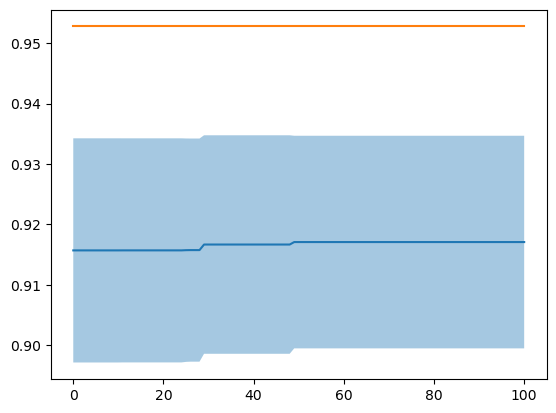

In [23]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame(data, columns = ['best', 'mean', 'std'])

plt.fill_between(df.index, df['mean']-df['std'], df['mean'] + df['std'], alpha=0.4)
plt.plot(df['mean'])
plt.plot(df['best'])

In [30]:
df.shape

(202, 3)

# Outputs

In [31]:
df_safe = library.molecules
df_safe.head()

,smiles,score
0,COC(=O)CC[C@H](C)NC(=O)[C@@]1(C)CC(c2cc(Cl)cc(...,0.939429
1,COC(=O)CCCNC(=O)[C@]1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1,0.935339
2,COC(=O)C1CC(NC(=O)[C@@]2(C)CC(c3cc(Cl)cc(Cl)c3...,0.928256
3,COC(=O)CCCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1,0.918479
4,COCCOC(=O)C[C@H](C)NC(=O)[C@@]1(C)CC(c2cc(Cl)c...,0.916851


In [32]:
len(df_safe)

1102

COC(=O)CCCNC(=O)[C@]1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1


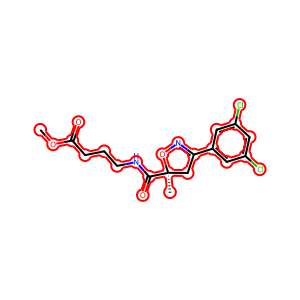

In [33]:
import safe as sf
print(df_safe.iloc[1,0])
sf.to_image(df_safe.iloc[1,0])


In [34]:
len(df_safe)

1102

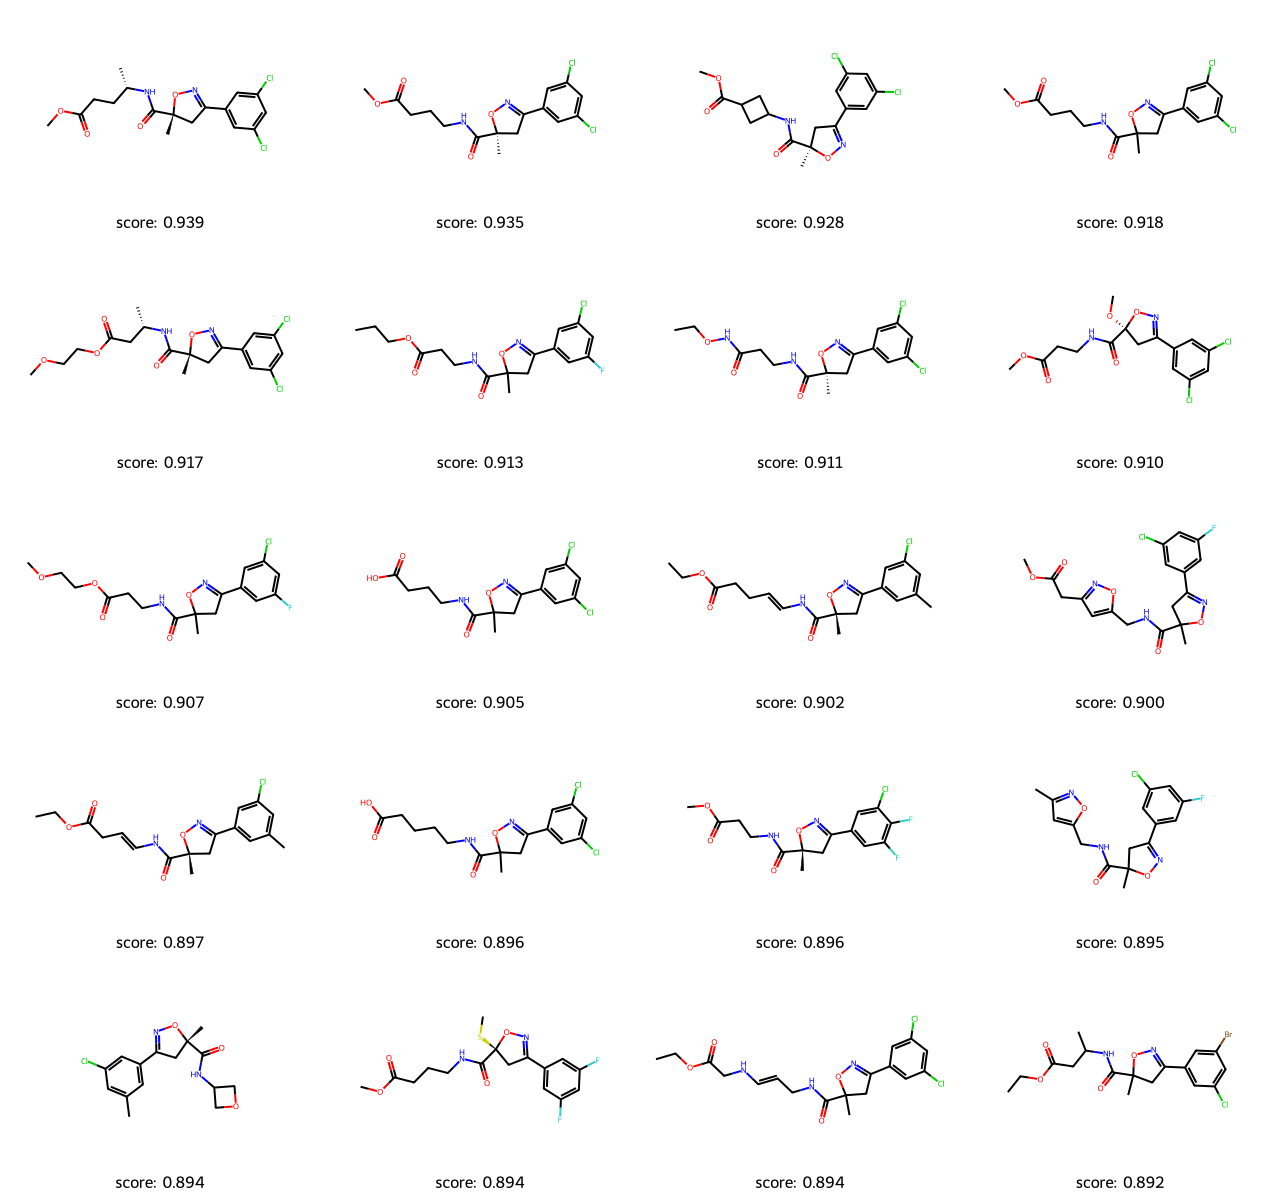

In [35]:
from rdkit.Chem import Draw
from rdkit import Chem
#select first 20
df_to_show = df_safe.iloc[0:20].copy()

#vis
ms = [Chem.MolFromSmiles(row['smiles']) for index, row in df_to_show.iterrows()]
legends = ['score: {:.3f}'.format(row['score']) for index, row in df_to_show.iterrows()]
#['score ' + str(row['score']) for index, row in df_to_show.iterrows()]
Draw.MolsToGridImage(ms, molsPerRow=4, subImgSize=(320, 240), legends=legends)


In [36]:
#df_safe.to_csv('../../data/processed/genmol/UKT_moo-w-qsar_R2.csv')